# Exploratory Data Analysis: IBM Telco Customer Churn

**Project:** Development and Evaluation of a Machine Learning Model for Predicting Customer Churn in the Telecommunications Industry.

This notebook is reproducible: it reads the local CSV (`data/raw/Telco-Customer-Churn.csv`, obtained with
`python scripts/download_data.py`) through the same loading and cleaning code used for model training
(`src/data_loader.py`). Figures are saved to `reports/figures/`.

**Dataset provenance.** The IBM Telco Customer Churn sample describes a *fictional* telecommunications company
providing phone and internet services to 7,043 customers. It is not data from any real company or from the
Ugandan market. All findings below are associations within this sample, not causal effects.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.config import FIGURES_DIR, RAW_DATA_PATH
from src.data_loader import check_quality, load_dataset, read_raw_csv
from src.eda import (add_tenure_band, association_with_churn, churn_rate_by,
                     column_summary, highest_churn_groups)
from src.schema import CATEGORICAL_FEATURES, FEATURE_DESCRIPTIONS, NUMERIC_FEATURES

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
BLUE, ORANGE, INK2, GRID = "#2a78d6", "#eb6834", "#52514e", "#e1e0d9"
CHURN_COLORS = {"No": BLUE, "Yes": ORANGE}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "normal",
})
pd.set_option("display.width", 140)

def save(fig, name):
    fig.savefig(FIGURES_DIR / name, bbox_inches="tight", dpi=150)

## 1. Raw data: dimensions, types and quality checks

In [2]:
raw = read_raw_csv(RAW_DATA_PATH)
print("Shape:", raw.shape)
raw.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.3,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.7,151.65,Yes


In [3]:
quality = check_quality(raw)
pd.Series(quality.to_dict(), name="value").to_frame()

,value
n_rows,7043
n_columns,21
missing_columns,[]
unexpected_columns,[]
missing_values,{'TotalCharges': 11}
blank_total_charges,11
blank_total_charges_with_zero_tenure,11
duplicate_rows,0
duplicate_ids,0
duplicate_feature_rows,22


**Findings.**
- All 21 expected columns are present; no unexpected target or category values.
- `TotalCharges` is stored as text and contains 11 blank values. Every one of them belongs to a customer with
  `tenure = 0`, i.e. a new customer who has not yet been billed, so the blank is set to **0** (not imputed with a
  statistic). Any other missing value would be imputed by the model pipeline using training-data statistics only.
- There are no duplicate customer IDs. A small number of rows are identical apart from `customerID`; they belong to
  different customers with the same attributes and are kept.

In [4]:
raw.loc[raw["TotalCharges"].str.strip() == "", ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20,,No
5218,2923-ARZLG,0,19.7,,No
6670,4075-WKNIU,0,73.35,,No


In [5]:
df = load_dataset(RAW_DATA_PATH)
column_summary(df, FEATURE_DESCRIPTIONS)

,column,type,missing,unique,example values,description
0,customerID,categorical,0,7043,"7590-VHVEG, 5575-GNVDE, 3668-QPYBK",Unique customer identifier (excluded from mode...
1,gender,categorical,0,2,"Female, Male",Customer gender (Female/Male).
2,SeniorCitizen,numeric,0,2,"0, 1","1 if the customer is 65 or older, otherwise 0."
3,Partner,categorical,0,2,"Yes, No",Whether the customer has a partner.
4,Dependents,categorical,0,2,"No, Yes",Whether the customer has dependents.
5,tenure,numeric,0,73,"1, 34, 2",Number of months the customer has stayed with ...
6,PhoneService,categorical,0,2,"No, Yes",Whether the customer has phone service.
7,MultipleLines,categorical,0,3,"No phone service, No, Yes",Whether the customer has multiple phone lines.
8,InternetService,categorical,0,3,"DSL, Fiber optic, No","Internet service type (DSL, Fiber optic, or no..."
9,OnlineSecurity,categorical,0,3,"No, Yes, No internet service",Whether the customer has the online security a...


## 2. Target class distribution

Churn
No     5174
Yes    1869
Name: count, dtype: int64 

Churn
No     0.7346
Yes    0.2654
Name: count, dtype: float64


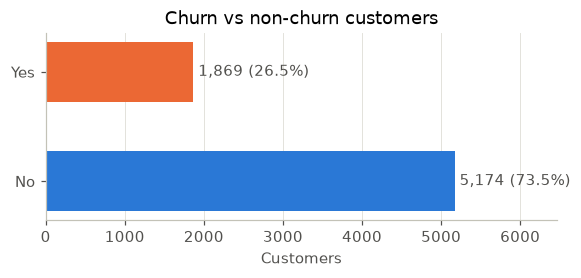

In [6]:
counts = df["Churn"].value_counts()
print(counts, "\n")
print((counts / len(df)).round(4))

fig, ax = plt.subplots(figsize=(6, 2.2))
ax.barh(counts.index, counts.values, color=[CHURN_COLORS[c] for c in counts.index], height=0.55)
for i, (label, v) in enumerate(counts.items()):
    ax.text(v + 60, i, f"{v:,} ({v / len(df):.1%})", va="center", color=INK2)
ax.set_xlabel("Customers"); ax.set_title("Churn vs non-churn customers"); ax.grid(axis="y", visible=False)
ax.set_xlim(0, counts.max() * 1.25)
save(fig, "01_class_distribution.png"); plt.show()

About 26.5% of customers churned. The classes are **imbalanced**: a model that always predicts "No" would be
about 73% accurate while identifying no churners, so accuracy alone is not a suitable evaluation metric.

## 3. Numerical features

In [7]:
df.groupby("Churn")[NUMERIC_FEATURES].describe().T.round(2)

Churn                      No      Yes
tenure         count  5174.00  1869.00
               mean     37.57    17.98
               std      24.11    19.53
               min       0.00     1.00
               25%      15.00     2.00
               50%      38.00    10.00
               75%      61.00    29.00
               max      72.00    72.00
MonthlyCharges count  5174.00  1869.00
               mean     61.27    74.44
               std      31.09    24.67
               min      18.25    18.85
               25%      25.10    56.15
               50%      64.43    79.65
               75%      88.40    94.20
               max     118.75   118.35
TotalCharges   count  5174.00  1869.00
               mean   2549.91  1531.80
               std    2329.95  1890.82
               min       0.00    18.85
               25%     572.90   134.50
               50%    1679.52   703.55
               75%    4262.85  2331.30
               max    8672.45  8684.80

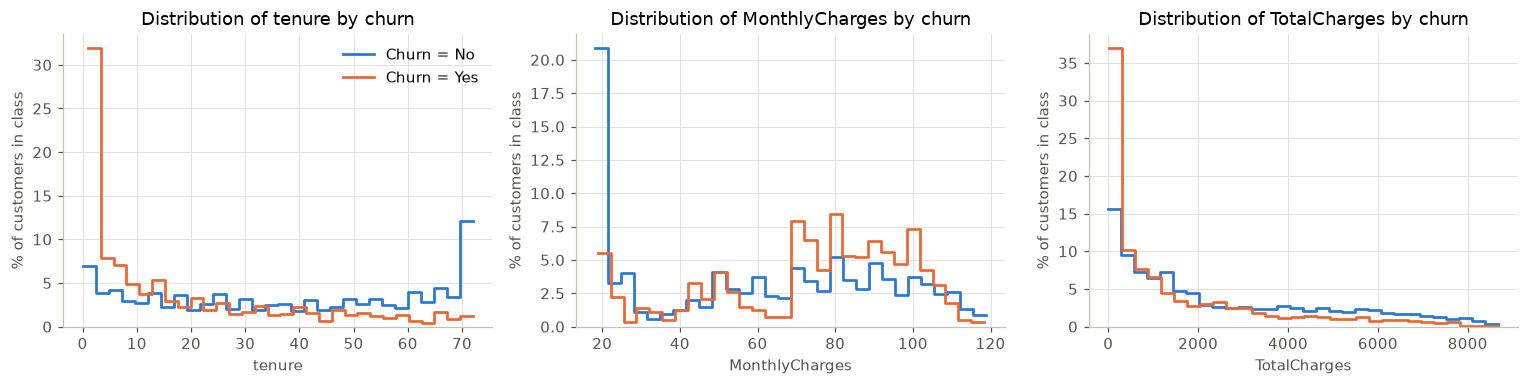

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, col in zip(axes, NUMERIC_FEATURES):
    for label in ["No", "Yes"]:
        sns.histplot(df.loc[df["Churn"] == label, col], ax=ax, stat="percent", bins=30, element="step",
                     fill=False, color=CHURN_COLORS[label], label=f"Churn = {label}", linewidth=1.8)
    ax.set_title(f"Distribution of {col} by churn"); ax.set_ylabel("% of customers in class")
axes[0].legend(frameon=False)
fig.tight_layout(); save(fig, "02_numeric_distributions.png"); plt.show()

- **Tenure:** churners are concentrated in the first months; long-tenure customers rarely churn.
- **MonthlyCharges:** churners tend to pay more per month (median about 80 vs 64 for non-churners); very low
  charges (around 20, typically phone-only customers) are dominated by non-churners.
- **TotalCharges:** lower for churners, largely because they have shorter tenure (the two are strongly correlated).

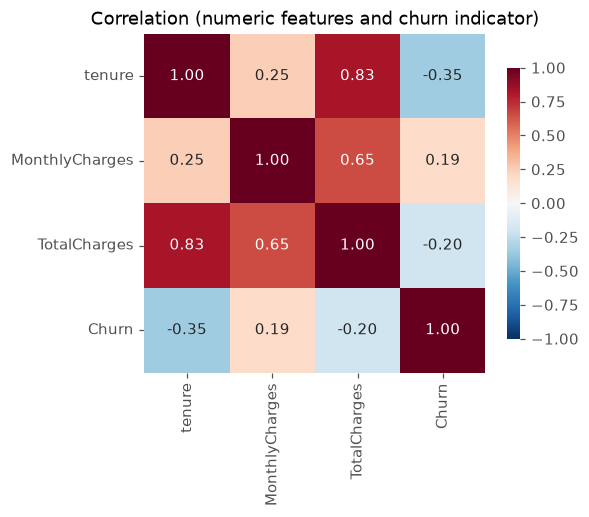

In [9]:
corr = df[NUMERIC_FEATURES].assign(Churn=(df["Churn"] == "Yes").astype(int)).corr()
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, cbar_kws={"shrink": 0.8})
ax.set_title("Correlation (numeric features and churn indicator)")
save(fig, "03_correlation.png"); plt.show()

`TotalCharges` is strongly correlated with `tenure` (r ≈ 0.83). This collinearity matters when interpreting
model coefficients or importances: the information in one is largely available in the other.

## 4. Categorical features and churn rates

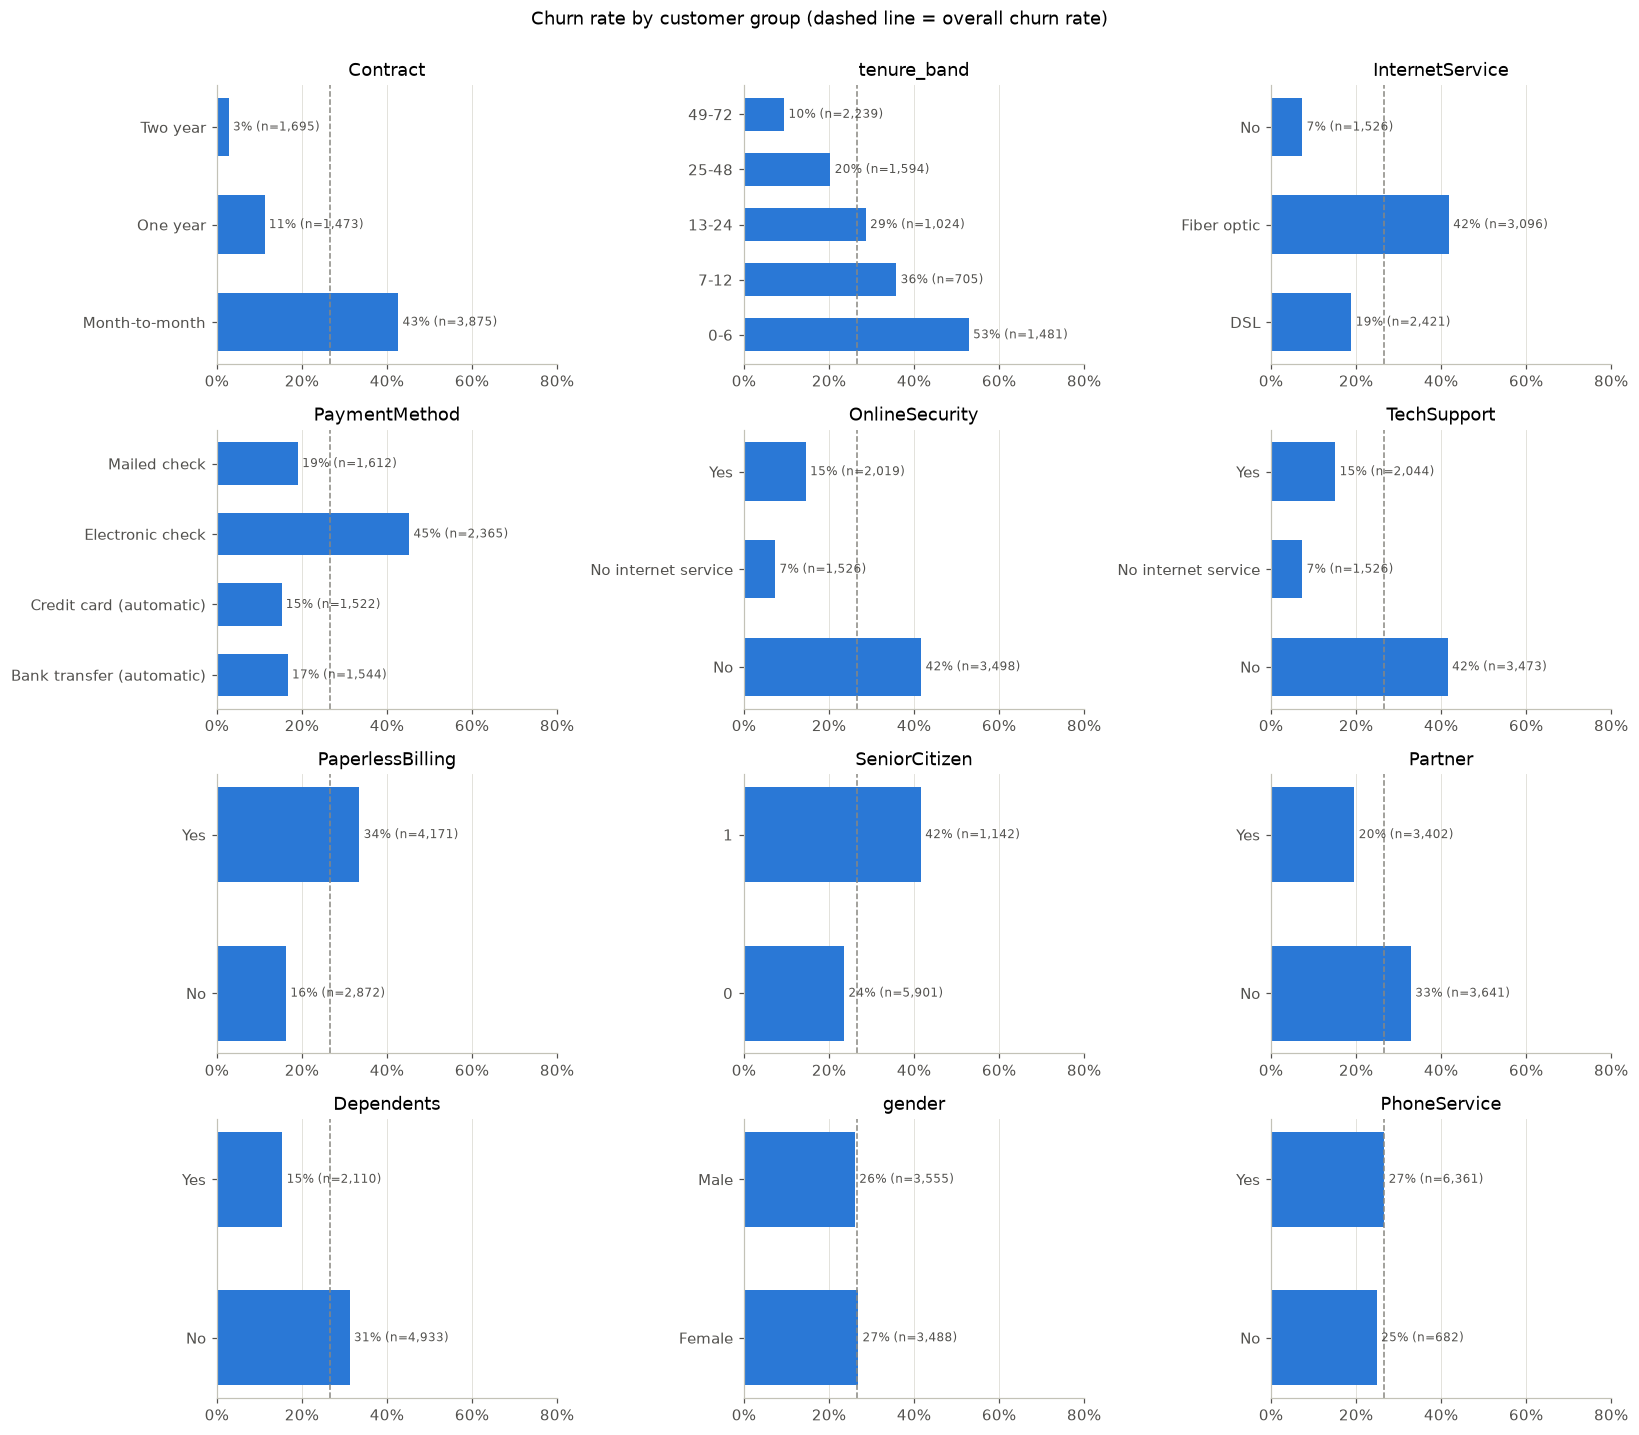

In [10]:
data = add_tenure_band(df)
groups = ["Contract", "tenure_band", "InternetService", "PaymentMethod", "OnlineSecurity", "TechSupport",
          "PaperlessBilling", "SeniorCitizen", "Partner", "Dependents", "gender", "PhoneService"]
overall = (df["Churn"] == "Yes").mean()
fig, axes = plt.subplots(4, 3, figsize=(15, 13))
for ax, col in zip(axes.ravel(), groups):
    t = churn_rate_by(data, col)
    ax.barh(t["group"].astype(str), t["churn_rate"], color=BLUE, height=0.6)
    ax.axvline(overall, color="#898781", linestyle="--", linewidth=1)
    for y, (r, n) in enumerate(zip(t["churn_rate"], t["customers"])):
        ax.text(r + 0.01, y, f"{r:.0%} (n={n:,})", va="center", fontsize=8, color=INK2)
    ax.set_xlim(0, 0.8); ax.set_title(col); ax.grid(axis="y", visible=False)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.suptitle("Churn rate by customer group (dashed line = overall churn rate)", y=1.0)
fig.tight_layout(); save(fig, "04_churn_rate_by_group.png"); plt.show()

In [11]:
highest_churn_groups(df, min_customers=200, top=10)

,feature,group,customers,churned,churn_rate
0,tenure_band,0-6,1481,784,0.529372
1,PaymentMethod,Electronic check,2365,1071,0.452854
2,Contract,Month-to-month,3875,1655,0.427097
3,InternetService,Fiber optic,3096,1297,0.418928
4,OnlineSecurity,No,3498,1461,0.417667
5,SeniorCitizen,1,1142,476,0.416813
6,TechSupport,No,3473,1446,0.416355
7,OnlineBackup,No,3088,1233,0.399288
8,DeviceProtection,No,3095,1211,0.391276
9,tenure_band,7-12,705,253,0.358865


**Observed patterns (associations, not causes):**
- Month-to-month contracts have much higher churn (~43%) than one-year (~11%) and two-year (~3%) contracts.
- Customers in their first six months churn at over 50%.
- Fibre-optic internet customers churn more (~42%) than DSL customers (~19%); fibre customers also pay higher
  monthly charges, so the two cannot be separated here.
- Electronic-check payers churn at ~45%, far above automatic payment methods (~15–17%).
- Customers without online security or technical support churn at ~42%.
- Gender and phone service show essentially no difference in churn rate.

## 5. Strength of association with churn

In [12]:
assoc = association_with_churn(df)
assoc.style.format({"strength": "{:.3f}", "p_value": "{:.2e}"})

,feature,type,measure,strength,p_value
0,Contract,categorical,Cramér's V,0.410,5.86e-258
1,tenure,numeric,point-biserial r,-0.352,2.42e-208
2,OnlineSecurity,categorical,Cramér's V,0.347,2.66e-185
3,TechSupport,categorical,Cramér's V,0.343,1.44e-180
4,InternetService,categorical,Cramér's V,0.322,9.57e-160
5,PaymentMethod,categorical,Cramér's V,0.303,3.68e-140
6,OnlineBackup,categorical,Cramér's V,0.292,2.08e-131
7,DeviceProtection,categorical,Cramér's V,0.281,5.51e-122
8,StreamingMovies,categorical,Cramér's V,0.230,2.67e-82
9,StreamingTV,categorical,Cramér's V,0.230,5.53e-82


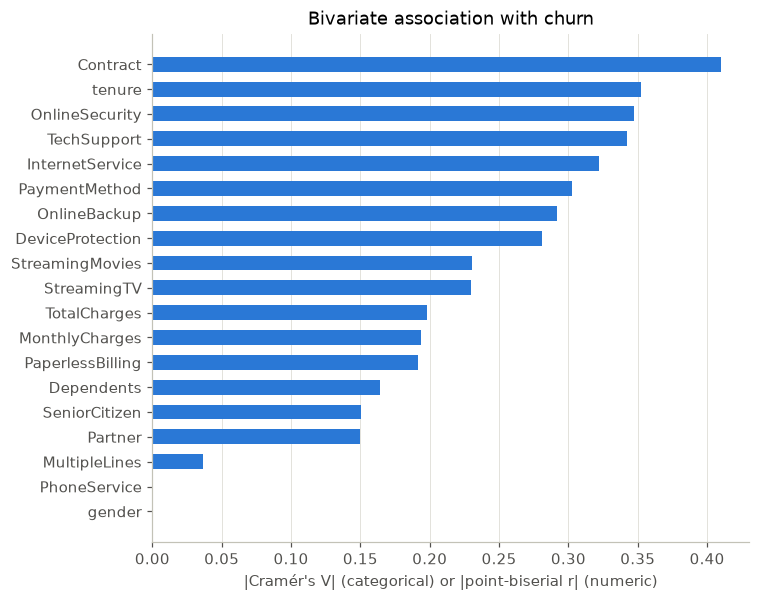

In [13]:
fig, ax = plt.subplots(figsize=(7, 6))
a = assoc.assign(abs_strength=assoc["strength"].abs()).sort_values("abs_strength")
ax.barh(a["feature"], a["abs_strength"], color=BLUE, height=0.6)
ax.set_xlabel("|Cramér's V| (categorical) or |point-biserial r| (numeric)")
ax.set_title("Bivariate association with churn"); ax.grid(axis="y", visible=False)
save(fig, "05_association.png"); plt.show()

Contract type, tenure, online security, technical support, internet service and payment method show the
strongest bivariate associations with churn; gender and phone service show none. Note that p-values are tiny for
most features because the sample is large; effect size (the strength measure) is more informative than
significance here. Bivariate measures do not account for overlaps between features (for example, month-to-month
customers also tend to have short tenure).

## 6. Implications for modelling

1. `customerID` is an identifier with no predictive meaning and is excluded.
2. Blank `TotalCharges` → 0 for tenure-0 customers; median imputation inside the pipeline as a safeguard.
3. Numeric features are standardised (needed for Logistic Regression), categoricals one-hot encoded.
4. Class imbalance (26.5% churn) is handled with class weighting and evaluated with recall, precision, F1,
   ROC-AUC and precision–recall curves rather than accuracy alone.
5. Correlated features (tenure / TotalCharges) call for care when interpreting importances.